# Model B — Startup Failure Risk Estimator

**Part of:** Startup Idea Failure Prediction and Recommendation System

**Purpose:** estimate a calibrated failure risk for a startup and convert it to a 0–100 risk score and a risk level.

## Design decisions (confirmed by the project owner)
| Decision | Choice |
|---|---|
| Target | `failure = 1` if `status == "closed"`, `0` if `status == "acquired"`. **No time horizon.** |
| Meaning of the score | `Risk Score = 100 × calibrated P(closed)`. It is a **relative risk estimate, not a "failure within N years" probability**. |
| Features | Only what a user could supply at idea/early stage: category, state, funding total, funding rounds, VC/angel flag, round A–D flags (+ features derived only from these). Lifetime-accumulated columns (relationships, milestones, ages of last events, avg participants, top500) are **dropped** to limit target leakage. |
| Split | **Time-based by founded year**: train ≤ 2005, calibration 2006–2007, test ≥ 2008. |
| Candidate models | Logistic Regression, Random Forest, CatBoost (same family as Model A) |
| Calibration | Platt scaling (sigmoid), fitted on the calibration slice only |

## Known limitations (documented up front)
* Every startup in the data is either *closed* or *acquired*. None is "still operating", so the model answers *"closed rather than acquired"*, not *"fails rather than survives"*.
* The dataset has no follow-up/observation-end date, so a precise time horizon cannot be defined.
* The data is US-only (state codes) and ends in 2013.
* `funding_total_usd`, `funding_rounds` and round flags are still cumulative up to the data snapshot, so some leakage remains. This is a trade-off you accepted.

## 1. Import libraries and configuration

In [1]:
import os, glob, json, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

SEED = 42
np.random.seed(SEED)

# ---- time-based split (by founded year) ----
TRAIN_END_YEAR = 2005      # train:       founded_year <= 2005
CALIB_END_YEAR = 2007      # calibration: 2006 .. 2007
                           # test:        founded_year >= 2008

# ---- risk levels (score = 100 * probability) ----
RISK_BINS   = [0, 25, 50, 75, 100.0001]
RISK_LABELS = ["Low", "Moderate", "High", "Very High"]

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Libraries loaded. Output dir:", OUTPUT_DIR)

Libraries loaded. Output dir: /kaggle/working


## 2. Load the dataset (Kaggle input path)

In [2]:
# Finds the CSV automatically under /kaggle/input (works for any dataset slug)
csv_candidates = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print("CSV files found:", csv_candidates)
assert csv_candidates, "No CSV found under /kaggle/input - add the dataset via 'Add Input'."
DATA_PATH = [p for p in csv_candidates if "startup" in os.path.basename(p).lower()][0]
print("Using:", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

CSV files found: ['/kaggle/input/datasets/mananpatel7310/startup-data/startup data.csv']
Using: /kaggle/input/datasets/mananpatel7310/startup-data/startup data.csv
Shape: (923, 49)


,Unnamed: 0,state_code,latitude,longitude,zip_code,id,city,Unnamed: 6,name,labels,founded_at,closed_at,first_funding_at,last_funding_at,age_first_funding_year,age_last_funding_year,age_first_milestone_year,age_last_milestone_year,relationships,funding_rounds,funding_total_usd,milestones,state_code.1,is_CA,is_NY,is_MA,is_TX,is_otherstate,category_code,is_software,is_web,is_mobile,is_enterprise,is_advertising,is_gamesvideo,is_ecommerce,is_biotech,is_consulting,is_othercategory,object_id,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,avg_participants,is_top500,status
0,1005,CA,42.358880,-71.056820,92101,c:6669,San Diego,NaN,Bandsintown,1,1/1/2007,NaN,4/1/2009,1/1/2010,2.2493,3.0027,4.6685,6.7041,3,3,375000,3,CA,1,0,0,0,0,music,0,0,0,0,0,0,0,0,0,1,c:6669,0,1,0,0,0,0,1.0000,0,acquired
1,204,CA,37.238916,-121.973718,95032,c:16283,Los Gatos,NaN,TriCipher,1,1/1/2000,NaN,2/14/2005,12/28/2009,5.1260,9.9973,7.0055,7.0055,9,4,40100000,1,CA,1,0,0,0,0,enterprise,0,0,0,1,0,0,0,0,0,0,c:16283,1,0,0,1,1,1,4.7500,1,acquired
2,1001,CA,32.901049,-117.192656,92121,c:65620,San Diego,San Diego CA 92121,Plixi,1,3/18/2009,NaN,3/30/2010,3/30/2010,1.0329,1.0329,1.4575,2.2055,5,1,2600000,2,CA,1,0,0,0,0,web,0,1,0,0,0,0,0,0,0,0,c:65620,0,0,1,0,0,0,4.0000,1,acquired
3,738,CA,37.320309,-122.050040,95014,c:42668,Cupertino,Cupertino CA 95014,Solidcore Systems,1,1/1/2002,NaN,2/17/2005,4/25/2007,3.1315,5.3151,6.0027,6.0027,5,3,40000000,1,CA,1,0,0,0,0,software,1,0,0,0,0,0,0,0,0,0,c:42668,0,0,0,1,1,1,3.3333,1,acquired
4,1002,CA,37.779281,-122.419236,94105,c:65806,San Francisco,San Francisco CA 94105,Inhale Digital,0,8/1/2010,10/1/2012,8/1/2010,4/1/2012,0.0000,1.6685,0.0384,0.0384,2,2,1300000,1,CA,1,0,0,0,0,games_video,0,0,0,0,0,1,0,0,0,0,c:65806,1,1,0,0,0,0,1.0000,1,closed


## 3. Initial inspection

In [3]:
display(raw.dtypes.to_frame("dtype").T)
miss = raw.isna().sum()
print("Columns with missing values:\n", miss[miss > 0])
print("\nstatus counts:\n", raw["status"].value_counts())
print("\nlabels vs status consistent (labels=1 <=> acquired):",
      bool((raw["labels"] == (raw["status"] == "acquired").astype(int)).all()))

,Unnamed: 0,state_code,latitude,longitude,zip_code,id,city,Unnamed: 6,name,labels,founded_at,closed_at,first_funding_at,last_funding_at,age_first_funding_year,age_last_funding_year,age_first_milestone_year,age_last_milestone_year,relationships,funding_rounds,funding_total_usd,milestones,state_code.1,is_CA,is_NY,is_MA,is_TX,is_otherstate,category_code,is_software,is_web,is_mobile,is_enterprise,is_advertising,is_gamesvideo,is_ecommerce,is_biotech,is_consulting,is_othercategory,object_id,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,avg_participants,is_top500,status
dtype,int64,object,float64,float64,object,object,object,object,object,int64,object,object,object,object,float64,float64,float64,float64,int64,int64,int64,int64,object,int64,int64,int64,int64,int64,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,object,int64,int64,int64,int64,int64,int64,float64,int64,object


Columns with missing values:
 Unnamed: 6                  493
closed_at                   588
age_first_milestone_year    152
age_last_milestone_year     152
state_code.1                  1
dtype: int64

status counts:
 status
acquired    597
closed      326
Name: count, dtype: int64

labels vs status consistent (labels=1 <=> acquired): True


## 4. Data cleaning and target definition

* Remove duplicate startups (same `id`).
* Parse dates; derive `founded_year` (used **only** for the time split, never as a feature).
* Target: `failure = (status == "closed")`.
* Drop identifiers, location text, and index artefacts.

In [4]:
df = raw.copy()

# 1) duplicates
before = len(df)
df = df.drop_duplicates(subset="id").reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate startup row(s)")

# 2) dates
for c in ["founded_at", "closed_at", "first_funding_at", "last_funding_at"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")
df["founded_year"] = df["founded_at"].dt.year
assert df["founded_year"].notna().all(), "Rows with unparseable founded_at"

# 3) target
assert set(df["status"].unique()) <= {"closed", "acquired"}
df["failure"] = (df["status"] == "closed").astype(int)

# 4) data-quality note: closed_at earlier than founded_at (not used for modelling)
bad_dates = ((df["closed_at"] - df["founded_at"]).dt.days < 0).sum()
print(f"Rows where closed_at < founded_at: {bad_dates}  (closed_at is NOT used, so no impact)")

# 5) category / state tidy-up
df["category_code"] = df["category_code"].fillna("other").str.strip().str.lower()
df["state_code"]    = df["state_code"].fillna("other").str.strip().str.upper()

# 6) sanity checks on numeric inputs
assert (df["funding_total_usd"] > 0).all()
assert (df["funding_rounds"] >= 1).all()

print("Clean shape:", df.shape)
print("Failure rate (closed):", round(df["failure"].mean(), 3))

Dropped 1 duplicate startup row(s)
Rows where closed_at < founded_at: 3  (closed_at is NOT used, so no impact)
Clean shape: (922, 51)
Failure rate (closed): 0.354


## 5. Select allowed (non-leaky) columns

Columns **kept** are those a founder could state at idea/early stage. Everything else is explicitly listed as excluded so the decision is auditable.

In [5]:
BASE_FEATURES = ["category_code", "state_code", "funding_total_usd", "funding_rounds",
                 "has_VC", "has_angel", "has_roundA", "has_roundB", "has_roundC", "has_roundD"]

EXCLUDED = {
    "target / label":                     ["status", "labels", "failure(derived)"],
    "lifetime-accumulated (leakage risk)": ["relationships", "milestones", "age_first_milestone_year",
                                            "age_last_milestone_year", "age_first_funding_year",
                                            "age_last_funding_year", "avg_participants", "is_top500"],
    "dates (time split / leakage)":       ["founded_at", "closed_at", "first_funding_at", "last_funding_at"],
    "identifiers / location text":        ["id", "object_id", "name", "city", "zip_code", "latitude",
                                           "longitude", "Unnamed: 0", "Unnamed: 6", "state_code.1"],
    "redundant one-hot duplicates":       [c for c in df.columns if c.startswith("is_") and c != "is_top500"],
}
for k, v in EXCLUDED.items():
    print(f"{k:38s}: {len(v)} cols")
print("\nKept base features:", BASE_FEATURES)

target / label                        : 3 cols
lifetime-accumulated (leakage risk)   : 8 cols
dates (time split / leakage)          : 4 cols
identifiers / location text           : 10 cols
redundant one-hot duplicates          : 15 cols

Kept base features: ['category_code', 'state_code', 'funding_total_usd', 'funding_rounds', 'has_VC', 'has_angel', 'has_roundA', 'has_roundB', 'has_roundC', 'has_roundD']


## 6. Data visualization (exploratory)

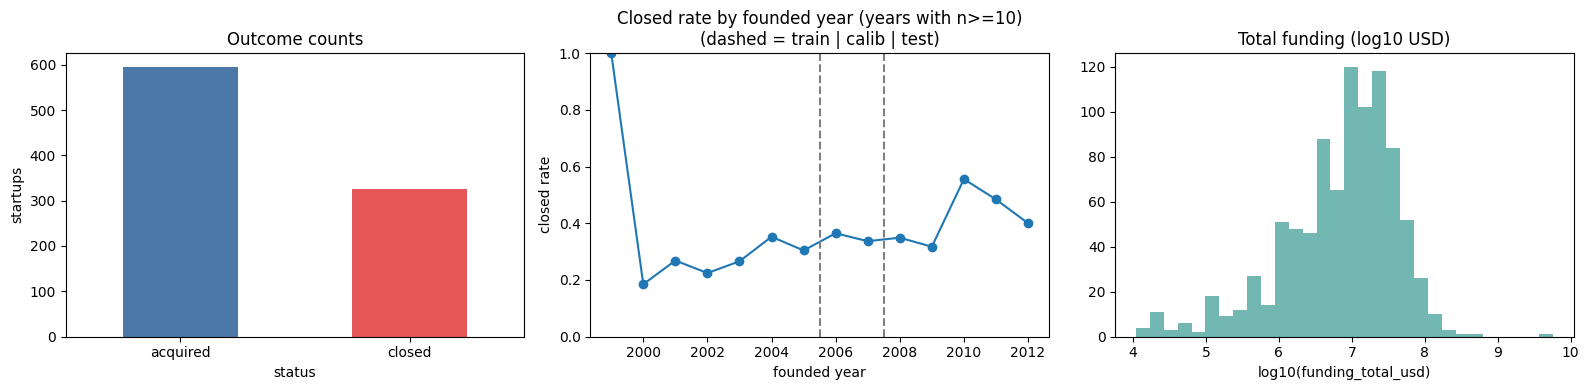

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df["status"].value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"])
ax[0].set_title("Outcome counts"); ax[0].set_ylabel("startups"); ax[0].tick_params(axis="x", rotation=0)

yr = df.groupby("founded_year")["failure"].agg(["mean", "size"])
yr = yr[yr["size"] >= 10]
ax[1].plot(yr.index, yr["mean"], marker="o"); ax[1].set_ylim(0, 1)
ax[1].axvline(TRAIN_END_YEAR + 0.5, color="gray", ls="--"); ax[1].axvline(CALIB_END_YEAR + 0.5, color="gray", ls="--")
ax[1].set_title("Closed rate by founded year (years with n>=10)\n(dashed = train | calib | test)")
ax[1].set_xlabel("founded year"); ax[1].set_ylabel("closed rate")

ax[2].hist(np.log10(df["funding_total_usd"]), bins=30, color="#72B7B2")
ax[2].set_title("Total funding (log10 USD)"); ax[2].set_xlabel("log10(funding_total_usd)")
plt.tight_layout(); plt.show()

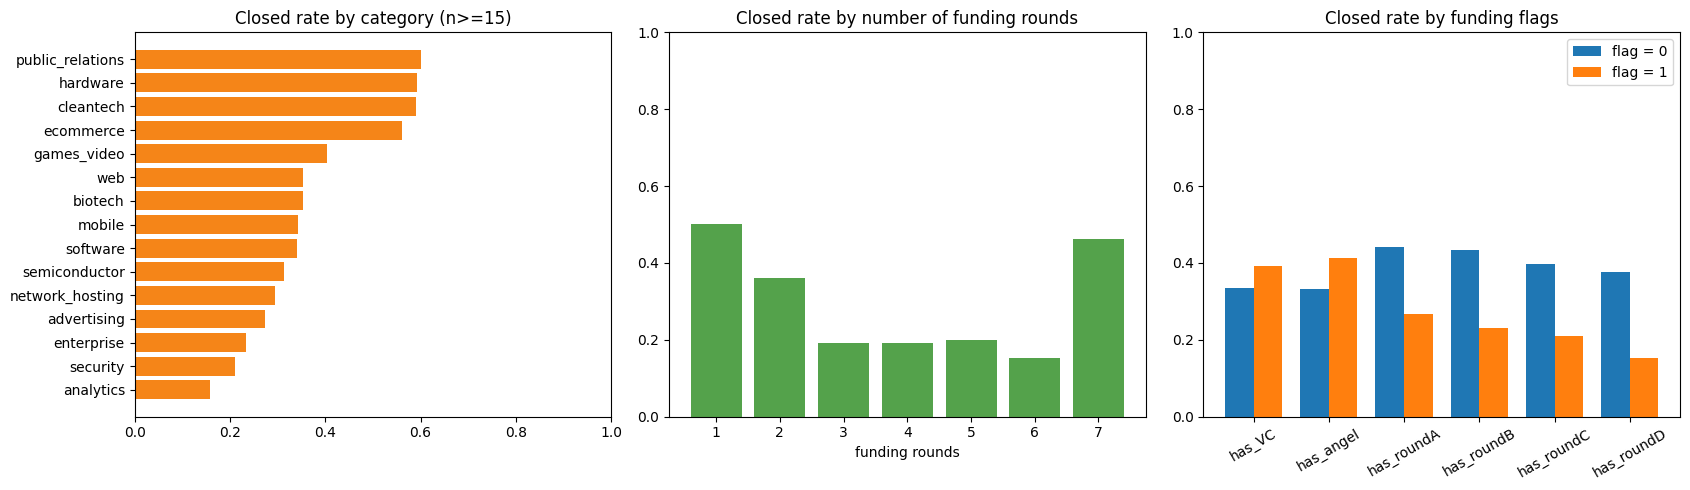

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

cat = df.groupby("category_code")["failure"].agg(["mean", "size"])
cat = cat[cat["size"] >= 15].sort_values("mean")
ax[0].barh(cat.index, cat["mean"], color="#F58518"); ax[0].set_title("Closed rate by category (n>=15)")
ax[0].set_xlim(0, 1)

rd = df.groupby("funding_rounds")["failure"].agg(["mean", "size"]); rd = rd[rd["size"] >= 10]
ax[1].bar(rd.index.astype(str), rd["mean"], color="#54A24B"); ax[1].set_ylim(0, 1)
ax[1].set_title("Closed rate by number of funding rounds"); ax[1].set_xlabel("funding rounds")

flags = ["has_VC", "has_angel", "has_roundA", "has_roundB", "has_roundC", "has_roundD"]
rates = {f: df.groupby(f)["failure"].mean() for f in flags}
x = np.arange(len(flags)); w = 0.38
ax[2].bar(x - w/2, [rates[f].get(0, np.nan) for f in flags], w, label="flag = 0")
ax[2].bar(x + w/2, [rates[f].get(1, np.nan) for f in flags], w, label="flag = 1")
ax[2].set_xticks(x); ax[2].set_xticklabels(flags, rotation=30); ax[2].set_ylim(0, 1)
ax[2].set_title("Closed rate by funding flags"); ax[2].legend()
plt.tight_layout(); plt.show()

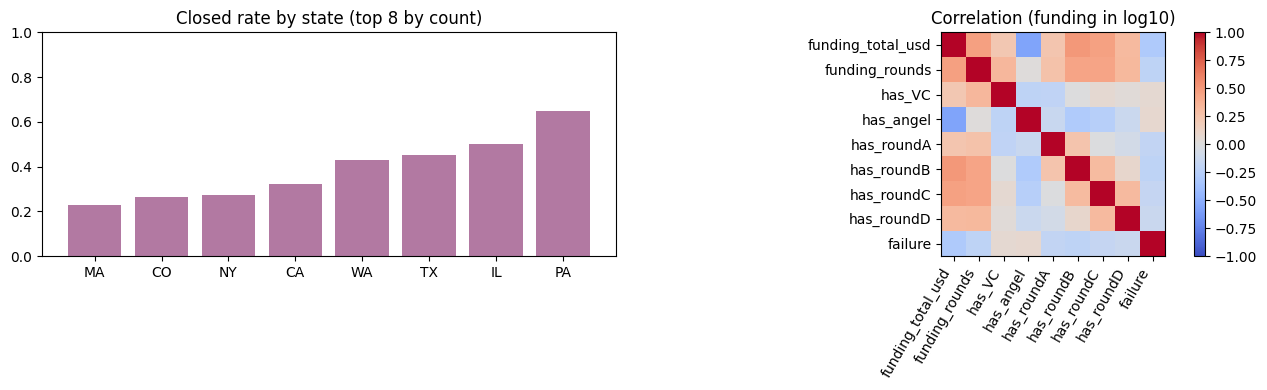

In [8]:
top_states = df["state_code"].value_counts().head(8).index
st = df[df["state_code"].isin(top_states)].groupby("state_code")["failure"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(st.index, st["mean"], color="#B279A2"); ax[0].set_ylim(0, 1); ax[0].set_title("Closed rate by state (top 8 by count)")
num = df[["funding_total_usd", "funding_rounds"] + flags + ["failure"]].copy()
num["funding_total_usd"] = np.log10(num["funding_total_usd"])
corr = num.corr()
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr))); ax[1].set_xticklabels(corr.columns, rotation=60, ha="right")
ax[1].set_yticks(range(len(corr))); ax[1].set_yticklabels(corr.columns)
ax[1].set_title("Correlation (funding in log10)"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## 7. Feature engineering

Only features computed from the allowed base columns are added:

* `log_funding_total` — funding is extremely skewed
* `funding_per_round` (log) — average size of a round
* `n_investor_types` — VC + angel indicators
* `highest_round` — highest of rounds A–D reached (0–4)
* `state_group` — CA / NY / MA / TX / other (very small states are otherwise too sparse)

Rare categories/states are also grouped inside the encoder (`min_frequency`), fitted on **train only**.

In [9]:
def engineer(d: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=d.index)
    out["category_code"]      = d["category_code"].astype(str).str.lower()
    out["state_group"]        = d["state_code"].astype(str).str.upper().where(
                                    d["state_code"].astype(str).str.upper().isin(["CA", "NY", "MA", "TX"]), "OTHER")
    out["log_funding_total"]  = np.log10(d["funding_total_usd"].clip(lower=1))
    out["funding_rounds"]     = d["funding_rounds"]
    out["funding_per_round"]  = np.log10((d["funding_total_usd"] / d["funding_rounds"].clip(lower=1)).clip(lower=1))
    for c in ["has_VC", "has_angel", "has_roundA", "has_roundB", "has_roundC", "has_roundD"]:
        out[c] = d[c].astype(int)
    out["n_investor_types"]   = out["has_VC"] + out["has_angel"]
    out["highest_round"]      = np.select([d["has_roundD"] == 1, d["has_roundC"] == 1,
                                           d["has_roundB"] == 1, d["has_roundA"] == 1], [4, 3, 2, 1], default=0)
    return out

X_all = engineer(df)
y_all = df["failure"].values

CAT_COLS = ["category_code", "state_group"]
NUM_COLS = [c for c in X_all.columns if c not in CAT_COLS]
print("Categorical:", CAT_COLS); print("Numeric    :", NUM_COLS)
X_all.head()

Categorical: ['category_code', 'state_group']
Numeric    : ['log_funding_total', 'funding_rounds', 'funding_per_round', 'has_VC', 'has_angel', 'has_roundA', 'has_roundB', 'has_roundC', 'has_roundD', 'n_investor_types', 'highest_round']


,category_code,state_group,log_funding_total,funding_rounds,funding_per_round,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,n_investor_types,highest_round
0,music,CA,5.574031,3,5.096910,0,1,0,0,0,0,1,0
1,enterprise,CA,7.603144,4,7.001084,1,0,0,1,1,1,1,4
2,web,CA,6.414973,1,6.414973,0,0,1,0,0,0,0,1
3,software,CA,7.602060,3,7.124939,0,0,0,1,1,1,0,4
4,games_video,CA,6.113943,2,5.812913,1,1,0,0,0,0,2,0


## 8. Time-based train / calibration / test split

In [10]:
yr = df["founded_year"]
idx_train = df.index[yr <= TRAIN_END_YEAR]
idx_cal   = df.index[(yr > TRAIN_END_YEAR) & (yr <= CALIB_END_YEAR)]
idx_test  = df.index[yr > CALIB_END_YEAR]

X_train, y_train = X_all.loc[idx_train], y_all[idx_train]
X_cal,   y_cal   = X_all.loc[idx_cal],   y_all[idx_cal]
X_test,  y_test  = X_all.loc[idx_test],  y_all[idx_test]

split_summary = pd.DataFrame({
    "split": ["train", "calibration", "test"],
    "founded_years": [f"<= {TRAIN_END_YEAR}", f"{TRAIN_END_YEAR+1}-{CALIB_END_YEAR}", f">= {CALIB_END_YEAR+1}"],
    "n": [len(idx_train), len(idx_cal), len(idx_test)],
    "closed_rate": [y_train.mean(), y_cal.mean(), y_test.mean()],
}).round(3)
display(split_summary)
print("Note: later cohorts have had less time to close, so closed_rate can drift (right-censoring).")

,split,founded_years,n,closed_rate
0,train,<= 2005,427,0.316
1,calibration,2006-2007,211,0.351
2,test,>= 2008,284,0.412


Note: later cohorts have had less time to close, so closed_rate can drift (right-censoring).


## 9. Model training and validation

Each candidate is fitted on the **train** slice only and compared on the **calibration/validation** slice (a later period than train), using ROC-AUC as the primary criterion. The **test** slice is not touched until the final evaluation.

In [11]:
def make_preprocessor(scale: bool):
    num_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=8, sparse_output=False), CAT_COLS),
        ("num", num_step, NUM_COLS),
    ])

candidates = {
    "LogisticRegression": Pipeline([
        ("pre", make_preprocessor(scale=True)),
        ("clf", LogisticRegression(C=0.5, max_iter=2000, random_state=SEED))]),
    "RandomForest": Pipeline([
        ("pre", make_preprocessor(scale=False)),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=10, max_features="sqrt",
                                       random_state=SEED, n_jobs=2))]),
    "CatBoost": Pipeline([
        ("pre", make_preprocessor(scale=False)),
        ("clf", CatBoostClassifier(iterations=300, depth=3, learning_rate=0.05, l2_leaf_reg=5,
                                   random_seed=SEED, verbose=0, thread_count=2))]),
}

val_rows = []
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_cal)[:, 1]
    val_rows.append({"model": name,
                     "val_roc_auc": roc_auc_score(y_cal, p),
                     "val_pr_auc": average_precision_score(y_cal, p),
                     "val_log_loss": log_loss(y_cal, p),
                     "val_brier": brier_score_loss(y_cal, p)})
val_table = pd.DataFrame(val_rows).set_index("model").round(4)
display(val_table)

best_name = val_table["val_roc_auc"].idxmax()
print("Selected model (highest validation ROC-AUC):", best_name)

,val_roc_auc,val_pr_auc,val_log_loss,val_brier
model,,,,
LogisticRegression,0.7081,0.6046,0.5751,0.1972
RandomForest,0.6907,0.5824,0.6142,0.2140
CatBoost,0.6425,0.5610,0.6464,0.2246


Selected model (highest validation ROC-AUC): LogisticRegression


## 10. Probability calibration (Platt scaling)

Raw model scores are not probabilities. A logistic (Platt) calibrator is fitted on the **calibration slice** (later in time than train, so it sees realistic out-of-sample scores). With only a few hundred calibration rows, sigmoid is chosen over isotonic to avoid overfitting; isotonic is shown for reference only.

In [12]:
from sklearn.isotonic import IsotonicRegression

def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

base_model = candidates[best_name]
p_cal_raw = base_model.predict_proba(X_cal)[:, 1]

platt = LogisticRegression(C=1e6, max_iter=1000)       # near-unregularised Platt scaling
platt.fit(to_logit(p_cal_raw), y_cal)

iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_cal_raw, y_cal)   # reference only

def calibrate(p_raw):
    return platt.predict_proba(to_logit(p_raw))[:, 1]

p_test_raw   = base_model.predict_proba(X_test)[:, 1]
p_test_cal   = calibrate(p_test_raw)
p_test_iso   = iso.predict(p_test_raw)
print("Calibrator slope/intercept:", platt.coef_.ravel().round(3), platt.intercept_.round(3))

Calibrator slope/intercept: [0.921] [-0.104]


## 11. Final evaluation on the held-out (latest-period) test set

In [13]:
def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); n = len(y); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi if hi < 1 else p <= hi)
        if m.sum(): e += m.sum() / n * abs(y[m].mean() - p[m].mean())
    return e

def metrics(y, p, thr=0.5):
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "log_loss": log_loss(y, np.clip(p, 1e-6, 1-1e-6)),
            "ECE": ece(y, p), "accuracy@0.5": accuracy_score(y, p >= thr), "F1@0.5": f1_score(y, p >= thr)}

res = pd.DataFrame({"raw": metrics(y_test, p_test_raw),
                    "calibrated (Platt) - FINAL": metrics(y_test, p_test_cal),
                    "isotonic (reference)": metrics(y_test, p_test_iso)}).T.round(4)
display(res)
print("Test base rate (closed):", round(y_test.mean(), 3), "| mean predicted risk (calibrated):", round(p_test_cal.mean(), 3))

,roc_auc,pr_auc,brier,log_loss,ECE,accuracy@0.5,F1@0.5
raw,0.7232,0.6651,0.2091,0.6066,0.0879,0.6620,0.6066
calibrated (Platt) - FINAL,0.7232,0.6651,0.2066,0.6014,0.0908,0.6796,0.6094
isotonic (reference),0.7131,0.6359,0.2126,0.9199,0.0961,0.7007,0.5550


Test base rate (closed): 0.412 | mean predicted risk (calibrated): 0.444


In [14]:
# Compare all candidates on the test set (raw scores) for the record - NOT used for selection
rows = {}
for name, pipe in candidates.items():
    rows[name] = metrics(y_test, pipe.predict_proba(X_test)[:, 1])
display(pd.DataFrame(rows).T.round(4))

,roc_auc,pr_auc,brier,log_loss,ECE,accuracy@0.5,F1@0.5
LogisticRegression,0.7232,0.6651,0.2091,0.6066,0.0879,0.6620,0.6066
RandomForest,0.7141,0.6480,0.2247,0.6384,0.0949,0.5880,0.6262
CatBoost,0.6588,0.5414,0.2302,0.6508,0.0875,0.6127,0.5802


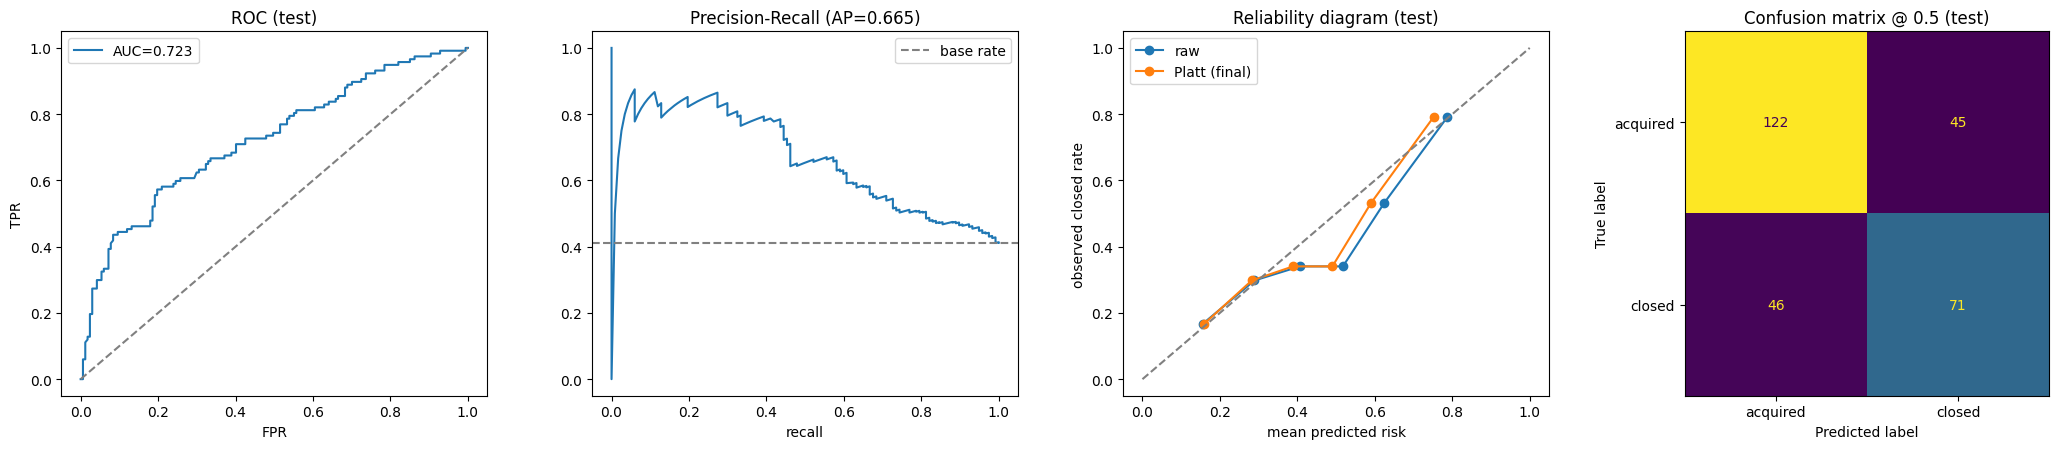

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.6))

fpr, tpr, _ = roc_curve(y_test, p_test_cal)
ax[0].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, p_test_cal):.3f}"); ax[0].plot([0,1],[0,1],"--",c="gray")
ax[0].set_title("ROC (test)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()

pr, rc, _ = precision_recall_curve(y_test, p_test_cal)
ax[1].plot(rc, pr); ax[1].axhline(y_test.mean(), ls="--", c="gray", label="base rate")
ax[1].set_title(f"Precision-Recall (AP={average_precision_score(y_test, p_test_cal):.3f})"); ax[1].set_xlabel("recall"); ax[1].legend()

for lab, p in [("raw", p_test_raw), ("Platt (final)", p_test_cal)]:
    fp, mp = calibration_curve(y_test, p, n_bins=6, strategy="quantile")
    ax[2].plot(mp, fp, marker="o", label=lab)
ax[2].plot([0,1],[0,1],"--",c="gray"); ax[2].set_title("Reliability diagram (test)")
ax[2].set_xlabel("mean predicted risk"); ax[2].set_ylabel("observed closed rate"); ax[2].legend()

ConfusionMatrixDisplay(confusion_matrix(y_test, p_test_cal >= 0.5), display_labels=["acquired", "closed"]).plot(ax=ax[3], colorbar=False)
ax[3].set_title("Confusion matrix @ 0.5 (test)")
plt.tight_layout(); plt.show()

In [16]:
# Uncertainty: bootstrap 95% CI on the test set
rng = np.random.default_rng(SEED)
aucs, briers = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].min() == y_test[i].max(): continue
    aucs.append(roc_auc_score(y_test[i], p_test_cal[i])); briers.append(brier_score_loss(y_test[i], p_test_cal[i]))
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
print(f"ROC-AUC 95% CI: {ci(aucs)[0]:.3f} - {ci(aucs)[1]:.3f}")
print(f"Brier   95% CI: {ci(briers)[0]:.3f} - {ci(briers)[1]:.3f}  (reference: always predicting the base rate = {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.3f})")

ROC-AUC 95% CI: 0.660 - 0.782
Brier   95% CI: 0.188 - 0.228  (reference: always predicting the base rate = 0.251)


## 12. Risk score, risk level and sanity check

,n,observed_closed_rate
risk_level,,
Low,58,0.207
Moderate,110,0.309
High,92,0.554
Very High,24,0.833


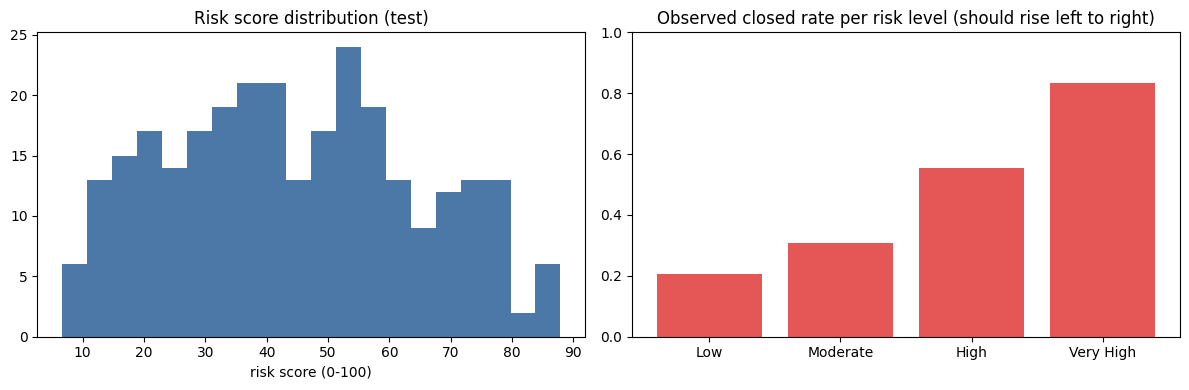

In [17]:
risk_score = 100 * p_test_cal
risk_level = pd.cut(risk_score, bins=RISK_BINS, labels=RISK_LABELS, right=False)
chk = (pd.DataFrame({"risk_level": risk_level, "closed": y_test})
         .groupby("risk_level", observed=False)["closed"].agg(n="size", observed_closed_rate="mean").round(3))
display(chk)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(risk_score, bins=20, color="#4C78A8"); ax[0].set_title("Risk score distribution (test)"); ax[0].set_xlabel("risk score (0-100)")
ax[1].bar(chk.index.astype(str), chk["observed_closed_rate"].fillna(0), color="#E45756"); ax[1].set_ylim(0, 1)
ax[1].set_title("Observed closed rate per risk level (should rise left to right)")
plt.tight_layout(); plt.show()

## 13. Contributing features

,feature,importance_mean,importance_std
2,log_funding_total,0.2745,0.0271
12,highest_round,0.0255,0.0088
7,has_roundA,0.0148,0.0064
1,state_group,0.0134,0.0101
0,category_code,0.0068,0.0133
5,has_VC,0.0038,0.0035
3,funding_rounds,0.0034,0.0060
6,has_angel,0.0023,0.0136
10,has_roundD,0.0003,0.0006
4,funding_per_round,0.0001,0.0091


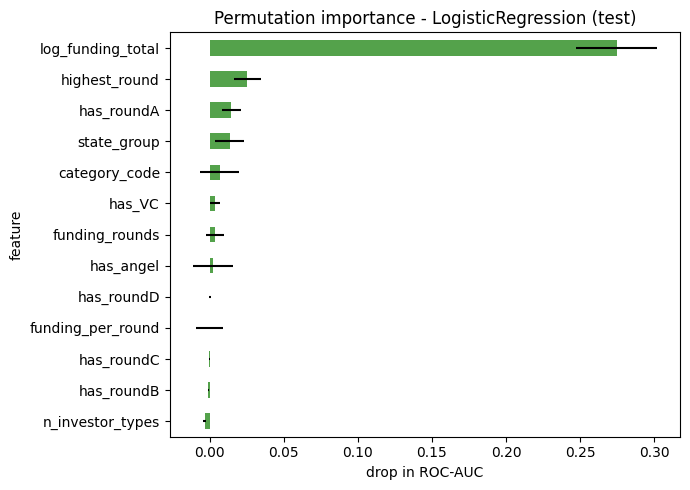

In [18]:
# Permutation importance of the FINAL base model on the test set (drop in ROC-AUC when a feature is shuffled)
pi = permutation_importance(base_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "importance_mean": pi.importances_mean,
                    "importance_std": pi.importances_std}).sort_values("importance_mean", ascending=False)
display(imp.round(4))
imp.sort_values("importance_mean").plot.barh(x="feature", y="importance_mean", xerr="importance_std",
                                             legend=False, figsize=(7, 5), color="#54A24B")
plt.title(f"Permutation importance - {best_name} (test)"); plt.xlabel("drop in ROC-AUC"); plt.tight_layout(); plt.show()

## 14. Inference module (single source of truth)

This code is written to `model_b_inference.py` and also executed here. The final app imports the same file, so notebook and production logic cannot drift apart.

It takes the structured form fields and returns the **risk probability, score 0-100, level, top contributing features and warnings** that the report builder (and later the LLM) will consume.

In [19]:
INFERENCE_SRC = r"""
import numpy as np
import pandas as pd

RISK_BINS   = [0, 25, 50, 75, 100.0001]
RISK_LABELS = ["Low", "Moderate", "High", "Very High"]

REQUIRED_FIELDS = ["category_code", "state_code", "funding_total_usd", "funding_rounds",
                   "has_VC", "has_angel", "has_roundA", "has_roundB", "has_roundC", "has_roundD"]

def _to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

def engineer(d):
    out = pd.DataFrame(index=d.index)
    out["category_code"] = d["category_code"].astype(str).str.lower()
    st = d["state_code"].astype(str).str.upper()
    out["state_group"] = st.where(st.isin(["CA", "NY", "MA", "TX"]), "OTHER")
    out["log_funding_total"] = np.log10(d["funding_total_usd"].clip(lower=1))
    out["funding_rounds"] = d["funding_rounds"]
    out["funding_per_round"] = np.log10((d["funding_total_usd"] / d["funding_rounds"].clip(lower=1)).clip(lower=1))
    for c in ["has_VC", "has_angel", "has_roundA", "has_roundB", "has_roundC", "has_roundD"]:
        out[c] = d[c].astype(int)
    out["n_investor_types"] = out["has_VC"] + out["has_angel"]
    out["highest_round"] = np.select([d["has_roundD"] == 1, d["has_roundC"] == 1,
                                      d["has_roundB"] == 1, d["has_roundA"] == 1], [4, 3, 2, 1], default=0)
    return out

def validate_input(rec):
    # Validate/normalise one startup record (dict). Returns (clean_dict, warnings).
    warnings, clean = [], dict(rec)
    missing = [k for k in REQUIRED_FIELDS if clean.get(k) is None]
    if missing:
        raise ValueError(f"Model B needs these fields: {missing}")
    clean["funding_total_usd"] = float(clean["funding_total_usd"])
    clean["funding_rounds"] = int(clean["funding_rounds"])
    if clean["funding_total_usd"] <= 0 or clean["funding_rounds"] < 1:
        raise ValueError("Model B was trained on funded startups: funding_total_usd > 0 and funding_rounds >= 1 required.")
    for k in ["has_VC", "has_angel", "has_roundA", "has_roundB", "has_roundC", "has_roundD"]:
        clean[k] = int(bool(clean[k]))
    return clean, warnings

def _predict_raw(bundle, X):
    p_raw = bundle["model"].predict_proba(X)[:, 1]
    return bundle["calibrator"].predict_proba(_to_logit(p_raw))[:, 1]

def predict_failure_risk(bundle, rec, top_k=4):
    clean, warnings = validate_input(rec)
    meta = bundle["metadata"]
    if clean["category_code"].lower() not in meta["known_categories"]:
        warnings.append(f"Category '{clean['category_code']}' was rare/unseen in training; it is treated as 'other/infrequent'.")
    if clean["state_code"].upper() not in meta["known_states"]:
        warnings.append("State/region not seen in training data (US-only data); location effect is treated as 'OTHER'.")
    lo, hi = meta["train_funding_range_usd"]
    if not (lo <= clean["funding_total_usd"] <= hi):
        warnings.append("Funding amount is outside the range seen in training; extrapolation is unreliable.")
    X = engineer(pd.DataFrame([clean]))
    p = float(_predict_raw(bundle, X)[0])
    score = 100 * p
    level = pd.cut([score], bins=RISK_BINS, labels=RISK_LABELS, right=False)[0]

    # local explanation by feature ablation (replace a feature by its training reference value)
    ref = pd.Series(meta["reference_values"])
    contribs = []
    for f in X.columns:
        Xa = X.copy(); Xa[f] = ref[f] if f in ref else Xa[f]
        if f in meta["numeric_features"]:
            Xa[f] = float(ref[f])
        contribs.append((f, X[f].iloc[0], p - float(_predict_raw(bundle, Xa)[0])))
    contribs.sort(key=lambda t: abs(t[2]), reverse=True)
    factors = [{"feature": f, "value": (v if isinstance(v, str) else float(v)),
                "effect_on_probability": round(d, 4),
                "direction": "raises risk" if d > 0 else "lowers risk"} for f, v, d in contribs[:top_k]]
    return {
        "failure_probability": round(p, 4),
        "risk_score": round(score, 1),
        "risk_level": str(level),
        "meaning": meta["score_meaning"],
        "top_contributing_features": factors,
        "model": meta["model_name"],
        "test_metrics": meta["test_metrics"],
        "warnings": warnings,
    }
"""
with open(os.path.join(OUTPUT_DIR, "model_b_inference.py"), "w") as f:
    f.write(INFERENCE_SRC)
exec(INFERENCE_SRC)
print("Wrote", os.path.join(OUTPUT_DIR, "model_b_inference.py"))

Wrote /kaggle/working/model_b_inference.py


## 15. Save the final model bundle

In [20]:
reference_values = {c: float(X_train[c].median()) for c in NUM_COLS}
reference_values.update({c: X_train[c].mode().iloc[0] for c in CAT_COLS})

metadata = {
    "model_name": f"{best_name} + Platt calibration",
    "target_definition": "failure = 1 if status == 'closed', 0 if status == 'acquired'. No time horizon. All startups in the data are closed or acquired.",
    "score_meaning": ("Risk Score = 100 x calibrated P(closed rather than acquired) among funded US startups in the training "
                      "data. A relative risk estimate - NOT a probability of failure within a specific number of years."),
    "features_used": list(X_all.columns), "categorical_features": CAT_COLS, "numeric_features": NUM_COLS,
    "excluded_for_leakage": EXCLUDED["lifetime-accumulated (leakage risk)"],
    "split": {"train": f"founded <= {TRAIN_END_YEAR}", "calibration": f"{TRAIN_END_YEAR+1}-{CALIB_END_YEAR}",
              "test": f"founded >= {CALIB_END_YEAR+1}", "n_train": int(len(y_train)), "n_cal": int(len(y_cal)), "n_test": int(len(y_test))},
    "calibration": "Platt scaling (sigmoid) fitted on the calibration slice",
    "risk_levels": dict(zip(RISK_LABELS, ["<25", "25-50", "50-75", ">=75"])),
    "test_metrics": {k: round(float(v), 4) for k, v in metrics(y_test, p_test_cal).items()},
    "test_roc_auc_95ci": [round(float(ci(aucs)[0]), 3), round(float(ci(aucs)[1]), 3)],
    "validation_table": val_table.reset_index().to_dict(orient="records"),
    "known_categories": sorted(X_train["category_code"].value_counts()[lambda s: s >= 8].index.tolist()),
    "known_states": sorted(df.loc[idx_train, "state_code"].unique().tolist()),
    "train_funding_range_usd": [float(df.loc[idx_train, "funding_total_usd"].min()), float(df.loc[idx_train, "funding_total_usd"].max())],
    "reference_values": reference_values,
    "permutation_importance": imp.round(4).to_dict(orient="records"),
    "data_provenance": f"Kaggle startup dataset ({os.path.basename(DATA_PATH)}), {len(df)} US startups founded 1984-2013, status closed/acquired.",
    "limitations": [
        "No still-operating startups: model separates closed from acquired, not failed from surviving.",
        "No observation-end dates: no defined prediction horizon, so no 'within N years' claim.",
        "US-only, data ends in 2013; may not transfer to other countries or current markets.",
        "Funding total/rounds/round flags are cumulative to the snapshot date; residual leakage is possible.",
        "Only funded startups are represented; pre-funding ideas are out-of-distribution.",
        "Later cohorts are right-censored (less time to close), so the test closed rate may be understated.",
        "Risk level thresholds (25/50/75) are a convention, not learned from data.",
    ],
}

bundle = {"model": base_model, "calibrator": platt, "metadata": metadata}
joblib.dump(bundle, os.path.join(OUTPUT_DIR, "model_b_failure_risk.joblib"))
with open(os.path.join(OUTPUT_DIR, "model_b_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print(os.listdir(OUTPUT_DIR))

['model_b_inference.py', '__notebook__.ipynb', 'model_b_failure_risk.joblib', 'catboost_info', 'model_b_metadata.json']


## 16. Reload the saved model and test the inference function

In [21]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location("model_b_inference", os.path.join(OUTPUT_DIR, "model_b_inference.py"))
mb = importlib.util.module_from_spec(spec); spec.loader.exec_module(mb)
loaded = joblib.load(os.path.join(OUTPUT_DIR, "model_b_failure_risk.joblib"))

# consistency: reloaded bundle must reproduce the notebook predictions
p_chk = mb._predict_raw(loaded, X_test)
print("Max difference vs notebook predictions:", float(np.abs(p_chk - p_test_cal).max()))

example = {"category_code": "software", "state_code": "CA", "funding_total_usd": 2_000_000, "funding_rounds": 1,
           "has_VC": 0, "has_angel": 1, "has_roundA": 1, "has_roundB": 0, "has_roundC": 0, "has_roundD": 0}
print(json.dumps(mb.predict_failure_risk(loaded, example), indent=2))

Max difference vs notebook predictions: 0.0
{
  "failure_probability": 0.2964,
  "risk_score": 29.6,
  "risk_level": "Moderate",
  "meaning": "Risk Score = 100 x calibrated P(closed rather than acquired) among funded US startups in the training data. A relative risk estimate - NOT a probability of failure within a specific number of years.",
  "top_contributing_features": [
    {
      "feature": "has_angel",
      "value": 1.0,
      "effect_on_probability": -0.2268,
      "direction": "lowers risk"
    },
    {
      "feature": "log_funding_total",
      "value": 6.301029995663981,
      "effect_on_probability": 0.1986,
      "direction": "raises risk"
    },
    {
      "feature": "funding_per_round",
      "value": 6.301029995663981,
      "effect_on_probability": -0.0661,
      "direction": "lowers risk"
    },
    {
      "feature": "has_roundA",
      "value": 1.0,
      "effect_on_probability": -0.066,
      "direction": "lowers risk"
    }
  ],
  "model": "LogisticRegression +

## 17. Summary and handoff to the report builder

* **Output contract (Model B):** `failure_probability`, `risk_score` (0–100), `risk_level`, `top_contributing_features`, `test_metrics`, `warnings`, and the `meaning` string that must be shown next to the score.
* **Files saved to `/kaggle/working`:** `model_b_failure_risk.joblib`, `model_b_inference.py`, `model_b_metadata.json`.
* **Reporting rule:** show the score as *"relative risk of closing rather than being acquired, among funded US startups"*; do not describe it as a probability of failure within N years.
* **Input gap to handle in the app:** Model B requires funding information (`funding_total_usd > 0`, `funding_rounds >= 1`). For pre-funding ideas the app should report that Model B is not applicable, not feed it made-up values.